This is a logistic regression model seeing how smoking habits in the UK can be predicted from factors like age, sex, socioeconomic status, marital status, education background, and race. 

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


Importing all necessaary packages for scikit-learn and matplot, as well as importing pandas

In [8]:
df = pd.read_csv("smoking.csv")
cols = [c for c in df.columns if c != "smoke"] + ["smoke"]
df = df[cols]
df = df.drop(columns=["nationality"])
df.head()

,Unnamed: 0,gender,age,marital_status,highest_qualification,ethnicity,gross_income,region,amt_weekends,amt_weekdays,type,smoke
0,1,Male,38,Divorced,No Qualification,White,"2,600 to 5,200",The North,NaN,NaN,NaN,No
1,2,Female,42,Single,No Qualification,White,"Under 2,600",The North,12.0,12.0,Packets,Yes
2,3,Male,40,Married,Degree,White,"28,600 to 36,400",The North,NaN,NaN,NaN,No
3,4,Female,40,Married,Degree,White,"10,400 to 15,600",The North,NaN,NaN,NaN,No
4,5,Female,39,Married,GCSE/O Level,White,"2,600 to 5,200",The North,NaN,NaN,NaN,No


Creates df to translate the .csv into a readable matrix for pandas, then puts the classifier ("smoke") at the last column of the dataset for readability, then removes "nationality" column as it makes meaningless disambiguations such as "british" vs. "english", then prints the first five rows to show what it's meant to look like.

In [9]:
df.info()
print(df.isna().sum())
print(df["smoke"].value_counts())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1691 entries, 0 to 1690
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             1691 non-null   int64  
 1   gender                 1691 non-null   str    
 2   age                    1691 non-null   int64  
 3   marital_status         1691 non-null   str    
 4   highest_qualification  1691 non-null   str    
 5   ethnicity              1691 non-null   str    
 6   gross_income           1691 non-null   str    
 7   region                 1691 non-null   str    
 8   amt_weekends           421 non-null    float64
 9   amt_weekdays           421 non-null    float64
 10  type                   421 non-null    str    
 11  smoke                  1691 non-null   str    
dtypes: float64(2), int64(2), str(8)
memory usage: 158.7 KB
Unnamed: 0                  0
gender                      0
age                         0
marital_status            

,Unnamed: 0,age,amt_weekends,amt_weekdays
count,1691.000000,1691.000000,421.000000,421.000000
mean,846.000000,49.836192,16.410926,13.750594
std,488.293969,18.736851,9.892988,9.388292
min,1.000000,16.000000,0.000000,0.000000
25%,423.500000,34.000000,10.000000,7.000000
50%,846.000000,48.000000,15.000000,12.000000
75%,1268.500000,65.500000,20.000000,20.000000
max,1691.000000,97.000000,60.000000,55.000000


Shows the amount of non-null responses for each variable, then shows the distribution of outcomes for the clasifying variable (smokers to non smokers ratio), then shows important facts for the numerical variables like the mean, std, and every quartile percentile (0, 25, 50, 75, 100).

In [10]:
X = df.drop(columns=["smoke"])
y = df["smoke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=67
)

Hides the classifying variable from the training data to make sure the model cannot predict the smoking outcome from directly the smoking outcome. Then, it does a train/test split with a stratification to keep an even proportion of smokers/non smokers between the train and test data, leaving less room for variability. Uses a 80/20 train/test split, a standard amount. 

In [11]:
num_cols = X.select_dtypes("number").columns
cat_cols = X.select_dtypes(exclude="number").columns

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

Cleans up the data by filling in missing values before running the models. For categorical variables, it uses the "most frequent" imputer, which will assign the most frequent value of that categorical variable to the missing values. For numerical values, it fills in missing values with the median. 

In [12]:
models = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "logreg": LogisticRegression(max_iter=1000),
}
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=10)
    print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

baseline: 0.751 ± 0.003
logreg: 0.842 ± 0.048


Shows the cross validation scores of our logistic regression as well as a dummy baseline model, to ensure that the logistic regrsession has SOME advantage over a completely arbitrary model. Used 10-fold cross validation because of dataset's small size.

              precision    recall  f1-score   support

          No       0.82      0.97      0.89       255
         Yes       0.79      0.37      0.50        84

    accuracy                           0.82       339
   macro avg       0.81      0.67      0.70       339
weighted avg       0.82      0.82      0.79       339



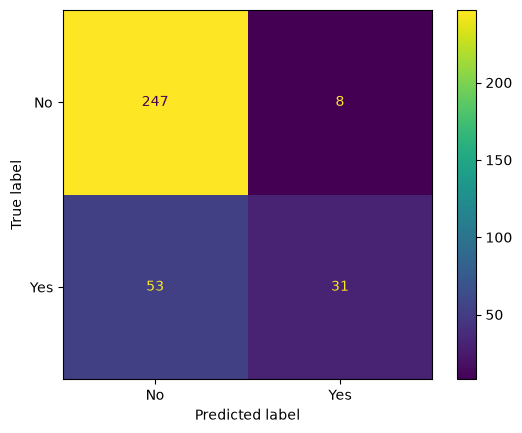

cat__type_Packets                              -3.284745
num__age                                       -0.753675
cat__region_The North                          -0.668676
cat__highest_qualification_Degree              -0.549062
cat__gross_income_Refused                      -0.542176
cat__region_Midlands & East Anglia             -0.528306
cat__gross_income_15,600 to 20,800             -0.490956
cat__marital_status_Married                    -0.477094
cat__ethnicity_Mixed                           -0.442967
cat__highest_qualification_A Levels            -0.390061
num__Unnamed: 0                                -0.316265
cat__gross_income_28,600 to 36,400             -0.243114
cat__ethnicity_Black                           -0.213329
cat__ethnicity_Chinese                         -0.156795
cat__gender_Male                               -0.118722
num__amt_weekends                              -0.113104
cat__ethnicity_Asian                           -0.106721
cat__highest_qualification_High

In [13]:
best_pipe = Pipeline([("prep", prep), ("model", models["logreg"])])
best_pipe.fit(X_train, y_train)
y_pred = best_pipe.predict(X_test)

print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()
feature_names = best_pipe.named_steps["prep"].get_feature_names_out()
coefs = best_pipe.named_steps["model"].coef_[0]
print(pd.Series(coefs, index=feature_names).sort_values())

Prints necessary results to show the chosen model's effectiveness.